# XGBoost — v1

**Van Nguyen Thanh Dat — 3124411067 · Nhóm 10 · UCI 697**

## Mục tiêu thí nghiệm

Đánh giá XGBoost với cấu hình cố định gồm 100 cây, độ sâu tối đa 3
và learning rate 0,1. Mô hình sử dụng 36 đặc trưng hiện có và được
đánh giá trên cùng 5 fold đã lưu của nhóm.

So sánh các mô hình bằng Macro-F1 trung bình trên 5 fold.
Dùng dự đoán OOF để phân tích kết quả theo từng lớp, đặc biệt là
Enrolled. Tập Test được giữ cho lần đánh giá cuối.

In [2]:
from pathlib import Path
import sys

current_dir = Path.cwd()
search_dirs = (current_dir, *current_dir.parents)

FINAL = next(
    folder
    for folder in search_dirs
    if (folder / "src" / "data.py").is_file()
    and (folder / "data" / "raw" /"data.csv").is_file()
)

sys.path.insert(0, str(FINAL))

from src.data import LABELS, load_student_data

## Mục 2 - Dữ liệu và nhãn

In [3]:
from IPython.display import display


X, y = load_student_data()

print("Số mẫu:", len(y))
print("Số đặc trưng:", X.shape[1])

label_counts = y.value_counts().reindex(LABELS)
label_summary = label_counts.rename_axis("Nhãn").to_frame("Số mẫu")

display(label_summary)

Số mẫu: 4424
Số đặc trưng: 36


,Số mẫu
Nhãn,
Dropout,1421
Enrolled,794
Graduate,2209


## Mục 3 - Nạp bộ chia Train/Test và 5 fold

In [4]:
from src.data import load_splits


train_ids, test_ids, folds, split_manifest = load_splits()

X_train = X.iloc[train_ids]
y_train = y.iloc[train_ids]

print("Số mẫu Train:", len(y_train))
print("Số mẫu Test:", len(test_ids))
print("Số fold:", len(folds))

for fold_number, (fit_positions, valid_positions) in enumerate(folds, start=1):
    print(
        f"Fold {fold_number}: "
        f"{len(fit_positions)} mẫu huấn luyện, "
        f"{len(valid_positions)} mẫu validation"
    )

Số mẫu Train: 3539
Số mẫu Test: 885
Số fold: 5
Fold 1: 2831 mẫu huấn luyện, 708 mẫu validation
Fold 2: 2831 mẫu huấn luyện, 708 mẫu validation
Fold 3: 2831 mẫu huấn luyện, 708 mẫu validation
Fold 4: 2831 mẫu huấn luyện, 708 mẫu validation
Fold 5: 2832 mẫu huấn luyện, 707 mẫu validation


## Mục 4 - Đọc cấu hình và tạo XGBoost

In [9]:
from runpy import run_path

import yaml


MODEL_ID = "m04_xgboost"
MODEL_VERSION = "v1"

model_dir = FINAL / "models" / MODEL_ID / MODEL_VERSION
config_path = model_dir / "config.yaml"
train_path = model_dir / "train.py"

with config_path.open(encoding="utf-8") as file:
    config = yaml.safe_load(file)

model_code = run_path(str(train_path))
make_model = model_code["make_model"]
model = make_model(config)

print("Mô hình:", type(model).__name__)
display(config["params"])

Mô hình: StudentDropoutXGBoost


{'objective': 'multi:softprob',
 'n_estimators': 100,
 'max_depth': 3,
 'learning_rate': 0.1,
 'tree_method': 'hist',
 'random_state': 42}

## Mục 5 - Chọn run XGBoost v1 đã lưu

In [10]:
RUN_ID = "m04_xgboost_v1_20261105T014707_bc3ae52b"
run_dir = FINAL / "experiments" / "runs" / RUN_ID

if not run_dir.is_dir():
    raise FileNotFoundError(f"Không tìm thấy thư mục kết quả: {run_dir}")

print("Run ID:", RUN_ID)
print("Thư mục kết quả:", run_dir)

Run ID: m04_xgboost_v1_20261105T014707_bc3ae52b
Thư mục kết quả: c:\Users\Dat\Documents\Môn đang học\Máy học\Đồ án\final_codespaces\final\experiments\runs\m04_xgboost_v1_20261105T014707_bc3ae52b


## Mục 6 - Kết quả trên 5 fold

In [11]:
import json

import pandas as pd


fold_metrics = pd.read_csv(run_dir / "fold_metrics.csv")

with (run_dir / "metrics.json").open(encoding="utf-8") as file:
    metrics = json.load(file)

cv = metrics["cv"]

fold_summary = fold_metrics[
    ["fold", "train_f1_macro", "valid_f1_macro"]
].rename(
    columns={
        "fold": "Fold",
        "train_f1_macro": "Macro-F1 Train",
        "valid_f1_macro": "Macro-F1 Validation",
    }
)

display(fold_summary.round(4))

print(
    f"Macro-F1 Validation CV: "
    f"{cv['valid_f1_macro_mean']:.4f} ± {cv['valid_f1_macro_std']:.4f}"
)
print(f"Chênh lệch Macro-F1 Train và Validation: {cv['gap_f1_macro_mean']:.4f}")

,Fold,Macro-F1 Train,Macro-F1 Validation
0,1,0.7605,0.7055
1,2,0.7723,0.7006
2,3,0.7703,0.7029
3,4,0.7722,0.6937
4,5,0.7787,0.6944


Macro-F1 Validation CV: 0.6994 ± 0.0046
Chênh lệch Macro-F1 Train và Validation: 0.0714


## Mục 7 - Kết quả OOF theo từng lớp

Mỗi dự đoán OOF được tạo khi mẫu tương ứng nằm trong phần validation
của một fold. Gộp các dự đoán này để đánh giá từng lớp trên 3.539 mẫu Train.

Accuracy OOF: 0.7771
Macro-F1 OOF: 0.6994


,precision,recall,F1,Số mẫu
Nhãn,,,,
Dropout,0.8270,0.7608,0.7925,1137
Enrolled,0.5649,0.3701,0.4472,635
Graduate,0.7944,0.9338,0.8585,1767


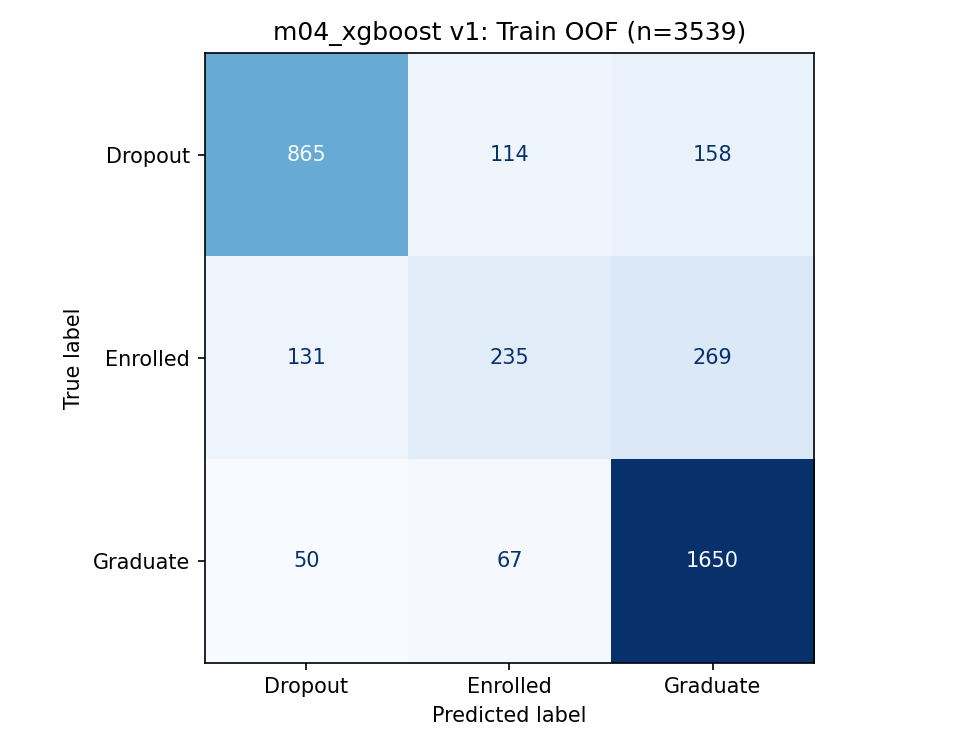

In [12]:
from IPython.display import Image


oof = metrics["oof"]
class_metrics = pd.read_csv(run_dir / "class_metrics_oof.csv")

class_summary = class_metrics.set_index("label").reindex(LABELS)
class_summary = class_summary.rename_axis("Nhãn").rename(
    columns={"f1-score": "F1", "support": "Số mẫu"}
)
class_summary["Số mẫu"] = class_summary["Số mẫu"].astype(int)

print(f"Accuracy OOF: {oof['accuracy']:.4f}")
print(f"Macro-F1 OOF: {oof['f1_macro']:.4f}")
display(class_summary.round(4))

confusion_matrix_path = run_dir / "figures" / "confusion_matrix.png"
display(Image(filename=str(confusion_matrix_path)))

## Mục 8 - Nhận xét và kết luận

- XGBoost v1 đạt Macro-F1 Validation CV **0,6994 ± 0,0046**
  trên 5 fold. Macro-F1 OOF gộp là **0,6994**.
- Lớp **Enrolled** có Recall OOF thấp nhất (**0,3701**).
  Mô hình nhận diện đúng **235/635** mẫu Enrolled. Các mẫu còn lại
  được dự đoán sang Dropout hoặc Graduate như bảng phía trên.
- Macro-F1 trung bình trên phần huấn luyện là **0,7708**,
  cao hơn phần validation **0,0714 điểm**.
- Theo Macro-F1 Validation CV, XGBoost v1 (**0,6994**) đứng sau
  Logistic Regression v2 (**0,7067**) và đứng trên Random Forest v1
  (**0,6852**) cùng Decision Tree v1 (**0,6472**).
- Tập Test gồm 885 mẫu được giữ cho lần đánh giá cuối sau khi nhóm
  chốt mô hình.

In [13]:
confusion_matrix = pd.read_csv(
    run_dir / "confusion_matrix.csv",
    index_col="true_label",
)

enrolled_predictions = confusion_matrix.loc["Enrolled", list(LABELS)]

display(
    enrolled_predictions
    .rename_axis("Nhãn dự đoán")
    .to_frame("Số mẫu Enrolled thực tế")
)

,Số mẫu Enrolled thực tế
Nhãn dự đoán,
Dropout,131
Enrolled,235
Graduate,269
